# Radioactive decay as a counting experiment

**Undergraduate project | Poisson statistics, simulation, and parameter estimation**

Suppose a detector records decay events in equal time bins. The underlying rate falls smoothly, but each observed bin contains an integer count that fluctuates. Can we recover the decay constant $\lambda$ from one noisy experiment?

We will simulate a known decay rate, fit $\lambda$ to the counts, and check whether the fluctuations are of the expected size. The data are **synthetic**. We assume a known, steady background rate and ideal counting without dead time; these simplifications let us focus on the statistical method.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.optimize import minimize

# Seed once: repeated experiments use successive draws rather than identical restarted samples.
rng = np.random.default_rng(25)


## 1. Counts at a fixed rate

If the expected number of events in one bin is $\mu$, an ideal Poisson model assigns probability

$$P(K=k\mid\mu)=\frac{e^{-\mu}\mu^k}{k!},\qquad k=0,1,2,\ldots$$

It predicts $\langle K\rangle=\mu$ and $\mathrm{Var}(K)=\mu$, so the standard deviation of a count is $\sqrt\mu$. **Task:** simulate 2,000 bins with the same expected count and compare their histogram, mean, and variance with these predictions.


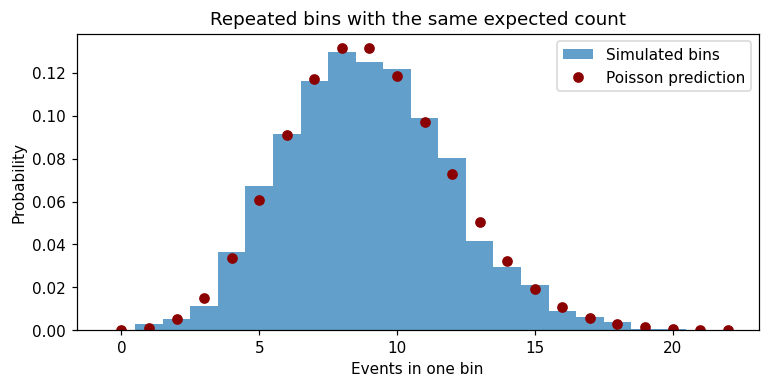

Observed mean: 8.94 | expected: 9
Observed sample variance: 8.923 | expected: 9
Observed standard deviation: 2.987 | expected: 3.0


In [2]:
expected = 9
# Each draw is one independent bin with the SAME expected count, not a decay trajectory.
fixed_counts = rng.poisson(expected, size=2000)
possible_counts = np.arange(0, 23)
probabilities = []
for k in possible_counts:
    # The Poisson probability is discrete: evaluate it at integer k, including zero.
    probabilities.append(np.exp(-expected)*expected**int(k)/math.factorial(int(k)))

plt.figure(figsize=(8, 3.5))
plt.hist(fixed_counts, bins=np.arange(-0.5, 22.5, 1), density=True,
         alpha=0.7, label='Simulated bins')
plt.plot(possible_counts, probabilities, 'o', color='darkred', label='Poisson prediction')
plt.xlabel('Events in one bin')
plt.ylabel('Probability')
plt.title('Repeated bins with the same expected count')
plt.legend()
plt.show()
print('Observed mean:', round(np.mean(fixed_counts), 3), '| expected:', expected)
print('Observed sample variance:', round(np.var(fixed_counts, ddof=1), 3), '| expected:', expected)
print('Observed standard deviation:', round(np.std(fixed_counts, ddof=1), 3), '| expected:', round(np.sqrt(expected), 3))


### Reading the fixed-rate histogram

The dots are theoretical probabilities for integer counts; the width-one bars are observed relative frequencies from 2,000 bins. Their shapes should agree approximately, while the sample mean and sample variance fluctuate around 9 and the standard deviation around 3. Exact equality is not expected from a finite experiment.

These bins all have the same expected count. Later decay bins have different means, so pooling them into one histogram would generally give a mixture rather than this single-mean Poisson distribution. The displayed range contains the current simulated sample; the unshown theoretical upper tail is not exactly zero.


## 2. A decaying rate

The number of undecayed nuclei follows $dN/dt=-\lambda N$, whose solution is $N(t)=N_0e^{-\lambda t}$. If the observed signal rate at $t=0$ is $R_0$, then $R(t)=R_0e^{-\lambda t}$. The half-life is

$$t_{1/2}=\frac{\ln 2}{\lambda}.$$

Counts are collected over intervals $[t_i,t_i+\Delta t]$, not at a single instant. Add a known constant background rate $b$. The **expected count in bin $i$** is

$$\mu_i=\int_{t_i}^{t_i+\Delta t}[R_0e^{-\lambda t}+b]\,dt
=\frac{R_0}{\lambda}\left(e^{-\lambda t_i}-e^{-\lambda(t_i+\Delta t)}\right)+b\Delta t.$$

We model separate bins as independent Poisson draws with these means. That is an idealized counting model; a detector observing one finite, fixed population of nuclei can require extra care about dependence and efficiency.


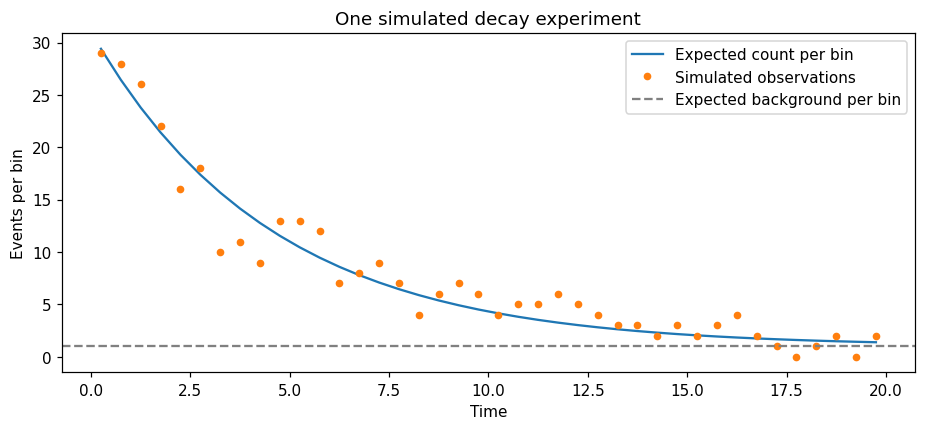

Total observed events: 318
Bins with zero observed events: 2


In [3]:
def expected_counts(start_times, width, initial_rate, decay_constant, background_rate):
    # Start with the signal RATE at each left bin edge.
    signal = initial_rate*np.exp(-decay_constant*start_times)
    # Integrate the exponential rate over the whole bin to obtain an expected COUNT.
    # -expm1(-lambda*width) evaluates 1-exp(-lambda*width) accurately for small arguments.
    # The fitted parameter bounds enforce lambda>0; lambda=0 would need its limit R0*width.
    signal = signal*(-np.expm1(-decay_constant*width))/decay_constant
    # Independent steady background adds its expected count b*width to each bin.
    background = background_rate*width
    return signal + background

width = 0.5
start_times = np.arange(0, 20, width)
# Bin centres locate integrated observations on a plot; the model still uses bin edges.
centers = start_times + width/2
true_initial_rate = 60.0
true_decay_constant = 0.22
background_rate = 2.0  # Assumed known from a separate background measurement

true_mean = expected_counts(start_times, width, true_initial_rate,
                            true_decay_constant, background_rate)
# Under the assumed independent Poisson model, fluctuations surround the integrated means.
counts = rng.poisson(true_mean)

plt.figure(figsize=(10, 4))
plt.plot(centers, true_mean, label='Expected count per bin')
plt.plot(centers, counts, 'o', markersize=4, label='Simulated observations')
plt.axhline(background_rate*width, color='gray', linestyle='--',
            label='Expected background per bin')
plt.xlabel('Time')
plt.ylabel('Events per bin')
plt.title('One simulated decay experiment')
plt.legend()
plt.show()
print('Total observed events:', sum(counts))
print('Bins with zero observed events:', sum(counts==0))


The points scatter around the decreasing rate. Late bins may contain very few events, but they still carry information. The curve above uses the **known inputs used to generate the synthetic data**; next we estimate $R_0$ and $\lambda$ from the counts instead.

## 3. Estimate the decay constant

For observed counts $k_i$, multiply the Poisson probabilities for all bins. Rather than multiply many small numbers, minimize the negative log-likelihood, omitting the $\log(k_i!)$ term because it does not depend on the parameters:

$$-\log L(R_0,\lambda)=\sum_i\left[\mu_i-k_i\log\mu_i\right]+\text{constant}.$$

**Task:** use the same expected-count function and find the positive $R_0$ and $\lambda$ that best describe the simulated bins. Keep the background rate fixed at its assumed known value. Unlike taking $\log(k_i-b\Delta t)$, this method can use bins with zero counts.


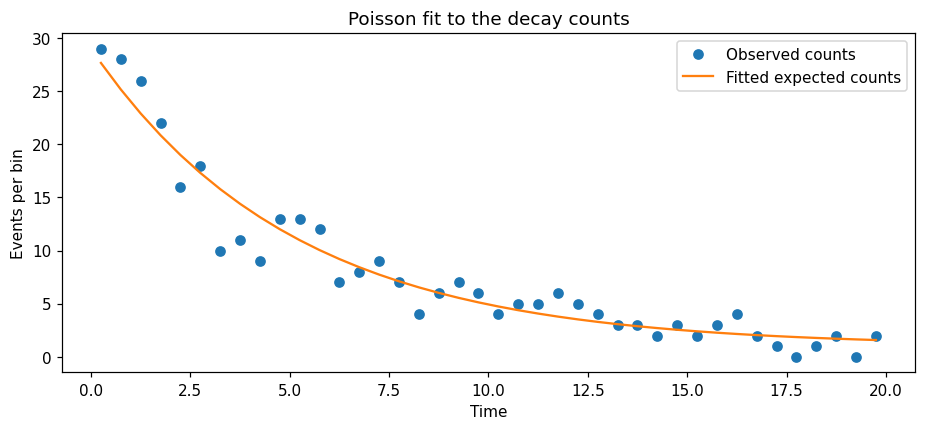

Estimated initial rate: 56.001 | simulated value: 60.0
Estimated decay constant: 0.1965 | simulated value: 0.22
Estimated half-life: 3.527 | simulated value: 3.151


In [4]:
def negative_log_likelihood(parameters, data, times, width, background_rate):
    initial_rate, decay_constant = parameters
    # Use the SAME integrated model for simulation and fitting, including known background.
    means = expected_counts(times, width, initial_rate,
                            decay_constant, background_rate)
    # Drop log(k!) because data are fixed during optimization; positive means allow k=0.
    # Do not log-transform background-subtracted observed counts.
    return np.sum(means - data*np.log(means))

def fit_decay(data, times, width, background_rate):
    # Approximate an initial signal rate from the first bin; this is only an optimizer start.
    first_guess = max(data[0]/width-background_rate, 1.0)
    # Bounds keep the model positive; these are search limits, not uncertainty intervals.
    result = minimize(negative_log_likelihood, [first_guess, 0.2],
                      args=(data, times, width, background_rate),
                      bounds=[(0.001, 500), (0.0001, 2.0)], method='L-BFGS-B')
    # A convergence failure must be reported rather than treated as a valid fitted experiment.
    if not result.success:
        raise RuntimeError('Fit did not converge: ' + result.message)
    return result.x

fitted_rate, fitted_decay = fit_decay(counts, start_times, width, background_rate)
fitted_half_life = np.log(2)/fitted_decay
fitted_mean = expected_counts(start_times, width, fitted_rate,
                              fitted_decay, background_rate)

print('Estimated initial rate:', round(fitted_rate, 3), '| simulated value:', true_initial_rate)
print('Estimated decay constant:', round(fitted_decay, 4), '| simulated value:', true_decay_constant)
print('Estimated half-life:', round(fitted_half_life, 3),
      '| simulated value:', round(np.log(2)/true_decay_constant, 3))

plt.figure(figsize=(10, 4))
plt.plot(centers, counts, 'o', label='Observed counts')
plt.plot(centers, fitted_mean, label='Fitted expected counts')
plt.xlabel('Time')
plt.ylabel('Events per bin')
plt.title('Poisson fit to the decay counts')
plt.legend()
plt.show()


### Interpreting the fitted curve

The curve predicts the **mean number of events integrated across each bin**, not an instantaneous rate evaluated at its centre. The fit estimates the initial signal rate and decay constant together while treating the background as known. Their fitted values fluctuate because the input is one noisy realization; the generating values are used only as synthetic-data benchmarks.

The optimizer bounds restrict the search to plausible positive values for this exercise. A boundary solution or a failure to converge would require investigation, rather than being read as an ordinary unconstrained estimate. A successful optimization alone does not verify the detector assumptions or supply an uncertainty interval.


The estimate need not exactly equal the value used in the simulation: we only observed **one noisy realization**. The fitted curve should follow the overall downward trend without passing through every count.

## 4. Are the fluctuations reasonable?

For a Poisson mean $\mu_i$, the expected standard deviation is $\sqrt{\mu_i}$. Use the fitted means to show a one-standard-deviation **reference band**, clipped at zero because counts cannot be negative. It is not an exact confidence interval for an individual discrete count. Also examine standardized residuals,

$$z_i=\frac{k_i-\widehat\mu_i}{\sqrt{\widehat\mu_i}}.$$

If the model is reasonable, residuals should scatter around zero with a scale of roughly one. Since bins have different means and the same data were used to fit the parameters, this is only a rough diagnostic.


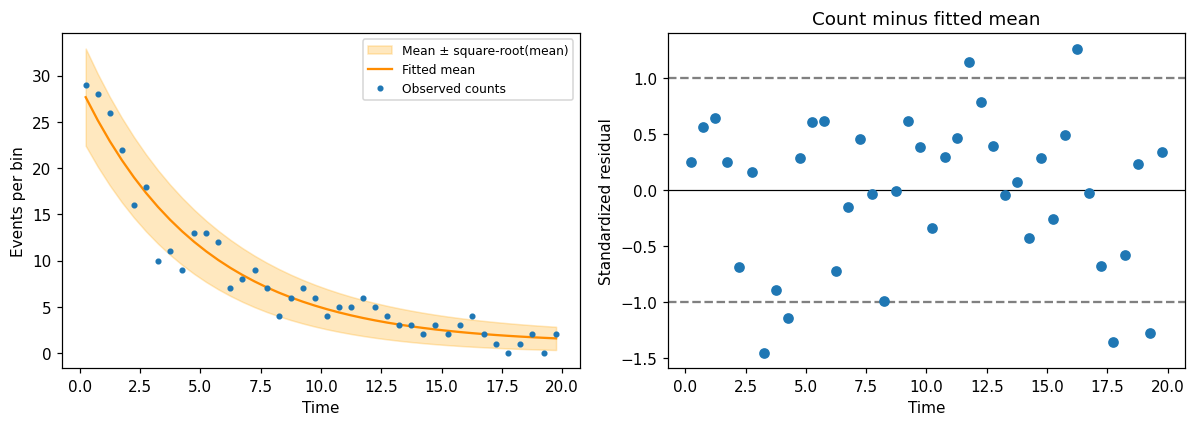

Mean standardized residual: -0.013
RMS standardized residual: 0.667


In [5]:
# Poisson counting spread concerns new counts at a given mean, not uncertainty in lambda.
counting_sigma = np.sqrt(fitted_mean)
# Standardize with expected variance, not sqrt(observed count), which fails for zero counts.
residual = (counts - fitted_mean)/counting_sigma

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.fill_between(centers, np.maximum(fitted_mean-counting_sigma, 0),
                 fitted_mean+counting_sigma, color='orange', alpha=0.25,
                 label='Mean ± square-root(mean)')
plt.plot(centers, fitted_mean, color='darkorange', label='Fitted mean')
plt.plot(centers, counts, 'o', markersize=3, label='Observed counts')
plt.xlabel('Time')
plt.ylabel('Events per bin')
plt.legend(fontsize=8)

plt.subplot(1, 2, 2)
plt.axhline(0, color='black', linewidth=0.8)
plt.axhline(1, color='gray', linestyle='--')
plt.axhline(-1, color='gray', linestyle='--')
plt.plot(centers, residual, 'o')
plt.xlabel('Time')
plt.ylabel('Standardized residual')
plt.title('Count minus fitted mean')
plt.tight_layout()
plt.show()
print('Mean standardized residual:', round(np.mean(residual), 3))
print('RMS standardized residual:', round(np.sqrt(np.mean(residual**2)), 3))


### Reading the reference band and residuals

The shaded band represents fitted mean plus or minus its square-root counting spread. It is **not** a confidence band for the mean curve or the fitted decay constant, nor an exact discrete prediction interval. Late-bin absolute fluctuations become smaller as the signal declines, while fluctuations relative to the total mean become larger and background becomes more important.

Residuals should have no obvious systematic time pattern if the model is adequate. At low means they are discrete and skewed, so they need not look Gaussian or mostly lie between ±1. Fitting parameters to these same counts also changes their joint behavior. The printed residual mean and RMS are rough diagnostics, not a calibrated goodness-of-fit test or a requirement that RMS equal exactly one.


## 5. How much might the estimate change? *(small extension)*

A fitted value is not the whole story. Generate 100 new experiments from the fitted model, refit each, and inspect the resulting decay constants. This is a **parametric bootstrap**: its spread depends on the model and assumed background being correct. We use percentile bounds as a rough interval for this teaching example, not as a guarantee for one dataset.


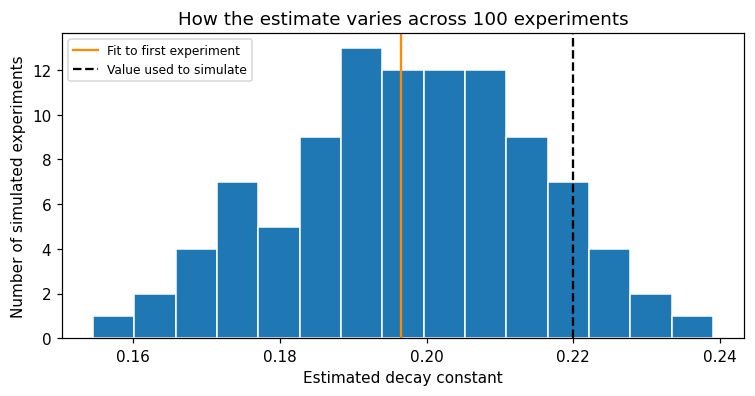

Bootstrap percentile range for decay constant: 0.1648 to 0.228
Corresponding half-life range: 3.04 to 4.207


In [6]:
bootstrap_decay = []
for trial in range(100):
    # Parametric bootstrap: simulate from the FITTED means, holding the assumed background fixed.
    new_counts = rng.poisson(fitted_mean)
    # Refit BOTH unknowns so amplitude uncertainty can affect the recovered decay constant.
    trial_rate, trial_decay = fit_decay(new_counts, start_times, width, background_rate)
    bootstrap_decay.append(trial_decay)

# Percentiles describe a rough model-based interval; 100 replicates give noisy tail estimates.
lower, upper = np.percentile(bootstrap_decay, [2.5, 97.5])
plt.figure(figsize=(8, 3.6))
plt.hist(bootstrap_decay, bins=15, edgecolor='white')
plt.axvline(fitted_decay, color='darkorange', label='Fit to first experiment')
plt.axvline(true_decay_constant, color='black', linestyle='--',
            label='Value used to simulate')
plt.xlabel('Estimated decay constant')
plt.ylabel('Number of simulated experiments')
plt.title('How the estimate varies across 100 experiments')
plt.legend(fontsize=8)
plt.show()
print('Bootstrap percentile range for decay constant:',
      round(lower, 4), 'to', round(upper, 4))
# Half-life decreases with lambda, so transform the upper lambda bound into the lower time bound.
print('Corresponding half-life range:',
      round(np.log(2)/upper, 3), 'to', round(np.log(2)/lower, 3))


### Reading the bootstrap distribution

Each histogram entry is a new fitted decay constant from an experiment generated using the first fit, not using the true generating parameters. The spread estimates how this fitting procedure varies under the fitted model and the same observation schedule. The original fit and the true value can lie at different places in that distribution.

The 2.5th and 97.5th percentiles give a rough percentile-bootstrap interval; only 100 replicates make its tails noisy. This is not a posterior probability distribution for the true decay constant, and one interval need not contain the known synthetic truth. Its interpretation depends on the Poisson model and fixed background being adequate. The half-life interval reverses the endpoints because (ln2/lambda) decreases as (lambda) increases.


## Conclusion

The decay law describes a smooth **mean rate**, while a detector reports noisy integer counts. Poisson fluctuations have variance equal to the expected count; their absolute size decreases as the rate falls, but their **fractional** size grows. Fitting all time bins with a Poisson likelihood recovers a decay constant and half-life from the synthetic experiment. The residual plot checks counting noise, and repeated simulated experiments illustrate uncertainty in the estimate.

**Assumptions to revisit with real data:** independently measured background, detection efficiency, time-bin width, and possible detector dead time. Do not treat the synthetic data here as a real isotope measurement.

**Python references:** [NumPy's Poisson random sampler](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.poisson.html) and [SciPy's bounded minimization](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html).
